In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df=pd.read_csv("C:/Users/navan/Downloads/telecom_network_intelligence_dataset_50500.csv") 
df.head()

,Flow_ID,Source_Node_ID,Destination_Node_ID,Protocol_Type,Source_Port,Destination_Port,Flow_Duration,Packet_Count,Byte_Count,Flow_Rate,...,Base_Station_ID,Device_Type,Service_Type,Session_Count,Mobility_Speed,Alarm_Type,Alarm_Severity,Failure_Count,Congestion_Level,Network_Status
0,FLOW_00000001,UE_001680,BS_0280,RTP,15652,5060,220.905,145,60755,0.1034,...,BS_0045,Smartphone,VoIP,1,32.21,NaN,NaN,0,NaN,Normal
1,FLOW_00000002,UE_005926,SRV_0017,TCP,6188,443,520.024,6082,5029814,0.7035,...,BS_0024,Enterprise_Device,Web_Browsing,1,0.00,NaN,NaN,0,Low,Normal
2,FLOW_00000003,UE_003457,BS_0291,TCP,27314,8080,519.877,69292,88485884,6.6616,...,BS_0162,Smartphone,Video_Streaming,1,67.64,High_Latency,Critical,0,Medium,Congested
3,FLOW_00000004,UE_002592,SRV_0215,MQTT,8334,5683,1372.757,1863,111780,0.2178,...,BS_0257,IoT_Sensor,IoT_Telemetry,6,3.64,NaN,NaN,0,NaN,Normal
4,FLOW_00000005,UE_003471,RTR_0087,HTTP2,58199,8080,2.286,5186,6658824,14.8509,...,BS_0103,Smartphone,Web_Browsing,6,56.06,NaN,NaN,0,NaN,Normal


In [2]:
df.shape

(50500, 34)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50500 entries, 0 to 50499
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Flow_ID                50500 non-null  object 
 1   Source_Node_ID         50500 non-null  object 
 2   Destination_Node_ID    50500 non-null  object 
 3   Protocol_Type          50500 non-null  object 
 4   Source_Port            50500 non-null  int64  
 5   Destination_Port       50500 non-null  int64  
 6   Flow_Duration          50500 non-null  float64
 7   Packet_Count           50500 non-null  int64  
 8   Byte_Count             50500 non-null  int64  
 9   Flow_Rate              50500 non-null  float64
 10  Throughput             50500 non-null  float64
 11  Latency                50500 non-null  float64
 12  Packet_Loss            50500 non-null  float64
 13  Jitter                 50500 non-null  float64
 14  Bandwidth_Utilization  50500 non-null  float64
 15  Li

In [4]:
#checking null values
df.isnull().sum()

Flow_ID                      0
Source_Node_ID               0
Destination_Node_ID          0
Protocol_Type                0
Source_Port                  0
Destination_Port             0
Flow_Duration                0
Packet_Count                 0
Byte_Count                   0
Flow_Rate                    0
Throughput                   0
Latency                      0
Packet_Loss                  0
Jitter                       0
Bandwidth_Utilization        0
Link_Utilization             0
Network_Load                 0
Active_Connections           0
Node_ID                      0
Node_Type                    0
Neighbor_Count               0
Hop_Count                    0
Link_Capacity                0
Cell_ID                      0
Base_Station_ID              0
Device_Type                  0
Service_Type                 0
Session_Count                0
Mobility_Speed               0
Alarm_Type               29713
Alarm_Severity           29713
Failure_Count                0
Congesti

,Missing_Count,Missing_Percent
Alarm_Type,29713,58.84
Alarm_Severity,29713,58.84
Congestion_Level,19282,38.18


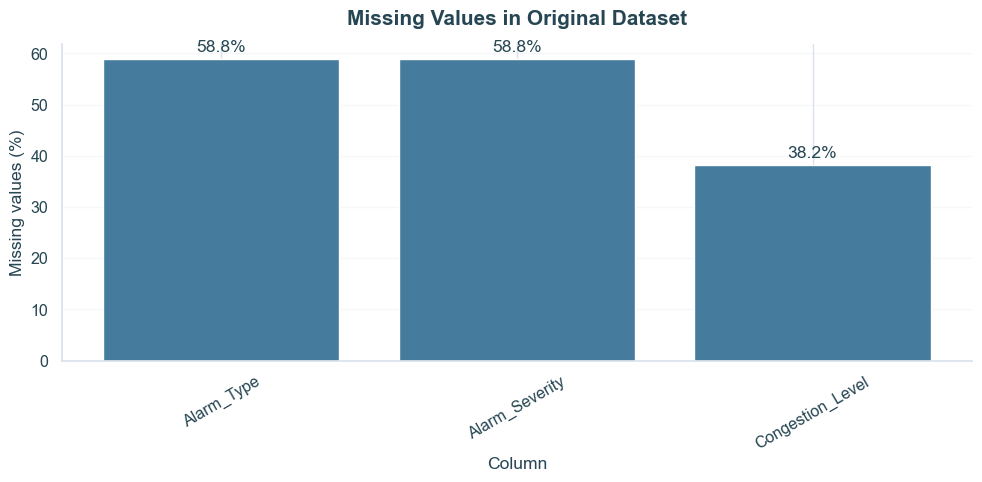

In [58]:
# Audit missing values in the original CSV BEFORE imputation
raw_df = pd.read_csv('C:/Users/navan/Downloads/telecom_network_intelligence_dataset_50500.csv')
missing_summary = (
    raw_df.isna().sum()
    .rename("Missing_Count")
    .to_frame()
)
missing_summary["Missing_Percent"] = (missing_summary["Missing_Count"] / len(raw_df) * 100).round(2)
missing_summary = missing_summary[missing_summary["Missing_Count"] > 0].sort_values("Missing_Count", ascending=False)
display(missing_summary)

# Optional: missing-value bar chart (only columns with missing values)
if not missing_summary.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(missing_summary.index, missing_summary["Missing_Percent"], color="#457B9D")
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in missing_summary["Missing_Percent"]], padding=3)
    ax.set_title("Missing Values in Original Dataset", fontsize=15, fontweight="bold", pad=14)
    ax.set_xlabel("Column")
    ax.set_ylabel("Missing values (%)")
    ax.tick_params(axis="x", rotation=30)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

In [5]:
# Columns to drop
drop_columns = [
    "Source_Node_ID",
    "Destination_Node_ID",
    "Source_Port",
    "Destination_Port",
    "Flow_Rate",
    "Link_Utilization",
    "Active_Connections",
    "Node_ID",
    "Node_Type",
    "Neighbor_Count",
    "Hop_Count",
    "Link_Capacity",
    "Cell_ID",
    "Base_Station_ID",
    "Device_Type",
    "Session_Count",
    "Mobility_Speed",
    "Alarm_Type",
    "Alarm_Severity"
]

# Drop columns
df.drop(columns=drop_columns, inplace=True)

# Check remaining columns
print(df.columns.tolist())
print("Dataset shape:", df.shape)

['Flow_ID', 'Protocol_Type', 'Flow_Duration', 'Packet_Count', 'Byte_Count', 'Throughput', 'Latency', 'Packet_Loss', 'Jitter', 'Bandwidth_Utilization', 'Network_Load', 'Service_Type', 'Failure_Count', 'Congestion_Level', 'Network_Status']
Dataset shape: (50500, 15)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50500 entries, 0 to 50499
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Flow_ID                50500 non-null  object 
 1   Protocol_Type          50500 non-null  object 
 2   Flow_Duration          50500 non-null  float64
 3   Packet_Count           50500 non-null  int64  
 4   Byte_Count             50500 non-null  int64  
 5   Throughput             50500 non-null  float64
 6   Latency                50500 non-null  float64
 7   Packet_Loss            50500 non-null  float64
 8   Jitter                 50500 non-null  float64
 9   Bandwidth_Utilization  50500 non-null  float64
 10  Network_Load           50500 non-null  float64
 11  Service_Type           50500 non-null  object 
 12  Failure_Count          50500 non-null  int64  
 13  Congestion_Level       31218 non-null  object 
 14  Network_Status         50500 non-null  object 
dtypes:

In [7]:
df['Congestion_Level'].isnull().sum()

np.int64(19282)

In [8]:
#percentage of null values
print(df["Congestion_Level"].isnull().mean() * 100)

38.182178217821786


In [9]:
print(df["Congestion_Level"].value_counts(dropna=False))

Congestion_Level
NaN       19282
Low       14457
High       8001
Medium     4924
Severe     3836
Name: count, dtype: int64


In [10]:
df['Congestion_Level'].mode()

0    Low
Name: Congestion_Level, dtype: object

In [11]:
df['Congestion_Level']=df['Congestion_Level'].fillna(df['Congestion_Level'].mode()[0])

In [12]:
print(df["Congestion_Level"].value_counts(dropna=False))

Congestion_Level
Low       33739
High       8001
Medium     4924
Severe     3836
Name: count, dtype: int64


In [13]:
print(df['Protocol_Type'].value_counts())

Protocol_Type
UDP      10693
TCP      10359
QUIC      9978
HTTP2     5525
HTTPS     4542
RTP       2662
SIP       1957
CoAP      1624
MQTT      1616
IPSec     1544
Name: count, dtype: int64


In [14]:
print(df['Service_Type'].value_counts())

Service_Type
Web_Browsing       11612
Video_Streaming    10690
IoT_Telemetry       6505
VoIP                6007
Messaging           4917
Enterprise_VPN      4633
Gaming              4145
AR_VR               1991
Name: count, dtype: int64


In [15]:
print(df['Network_Status'].value_counts())

Network_Status
Normal       34494
Congested    11022
Fault         4984
Name: count, dtype: int64


In [16]:
#duplicated values
print(df.duplicated().sum())

0


In [17]:
#check datatype
print(df.dtypes)

Flow_ID                   object
Protocol_Type             object
Flow_Duration            float64
Packet_Count               int64
Byte_Count                 int64
Throughput               float64
Latency                  float64
Packet_Loss              float64
Jitter                   float64
Bandwidth_Utilization    float64
Network_Load             float64
Service_Type              object
Failure_Count              int64
Congestion_Level          object
Network_Status            object
dtype: object


In [21]:
df.head()

,Flow_ID,Protocol_Type,Flow_Duration,Packet_Count,Byte_Count,Throughput,Latency,Packet_Loss,Jitter,Bandwidth_Utilization,Network_Load,Service_Type,Failure_Count,Congestion_Level,Network_Status
0,FLOW_00000001,RTP,220.905,145,60755,0.0897,26.463,0.4684,4.625,40.405,15.650,VoIP,0,Low,Normal
1,FLOW_00000002,TCP,520.024,6082,5029814,0.6325,14.851,0.4386,3.143,20.280,44.621,Web_Browsing,0,Low,Normal
2,FLOW_00000003,TCP,519.877,69292,88485884,6.0344,78.080,2.3449,30.547,87.927,86.616,Video_Streaming,0,Medium,Congested
3,FLOW_00000004,MQTT,1372.757,1863,111780,0.2189,36.255,0.1877,1.181,75.056,26.294,IoT_Telemetry,0,Low,Normal
4,FLOW_00000005,HTTP2,2.286,5186,6658824,13.8181,22.979,0.1661,4.226,36.957,37.454,Web_Browsing,0,Low,Normal


In [18]:
df.describe()

,Flow_Duration,Packet_Count,Byte_Count,Throughput,Latency,Packet_Loss,Jitter,Bandwidth_Utilization,Network_Load,Failure_Count
count,50500.000000,50500.000000,5.050000e+04,50500.000000,50500.000000,50500.000000,50500.000000,50500.000000,50500.000000,50500.000000
mean,1135.926693,22346.306396,1.692443e+07,5.996079,61.569902,1.819911,12.687479,53.593050,49.319745,0.381604
std,1515.626907,31024.091759,2.826977e+07,29.954584,63.795799,3.338947,15.492954,23.794731,24.765902,0.835568
min,0.050000,27.000000,2.738000e+03,0.001100,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,118.579500,1291.750000,3.383355e+05,0.236175,21.345000,0.140200,3.376000,35.909500,30.836000,0.000000
50%,518.570000,8081.500000,4.844890e+06,1.449350,32.086000,0.314450,6.108500,49.247000,43.518000,0.000000
75%,1518.098750,33761.250000,2.024006e+07,5.504725,87.278250,2.151750,16.183250,73.387250,69.485500,0.000000
max,7199.124000,251788.000000,3.303576e+08,4151.599300,460.125000,28.348900,125.222000,100.000000,100.000000,5.000000


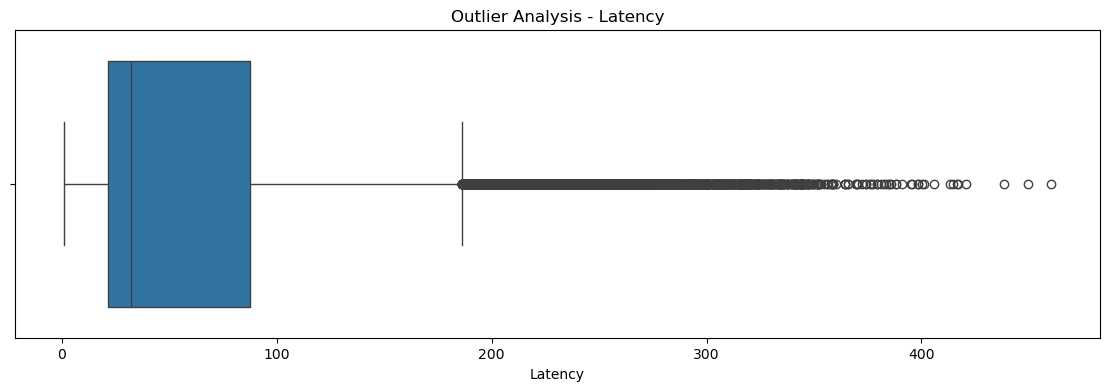

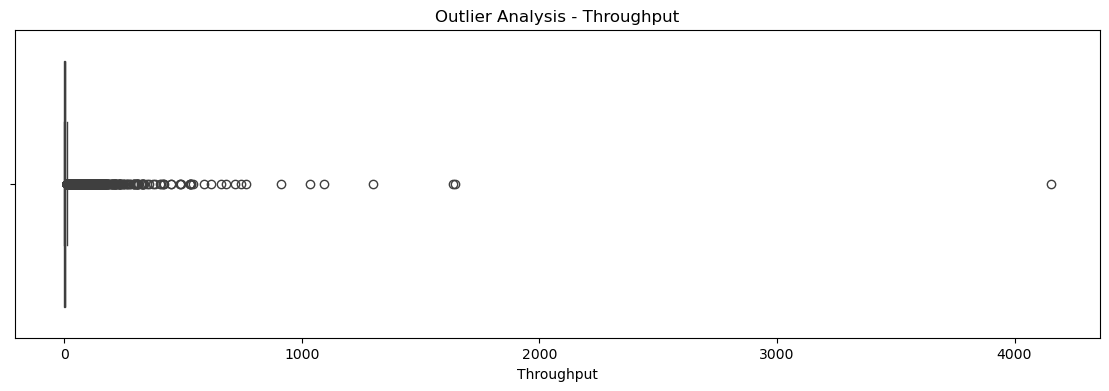

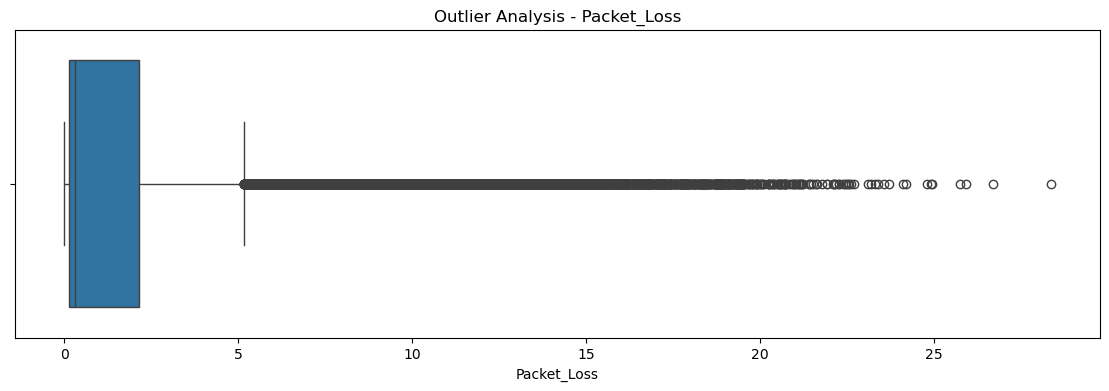

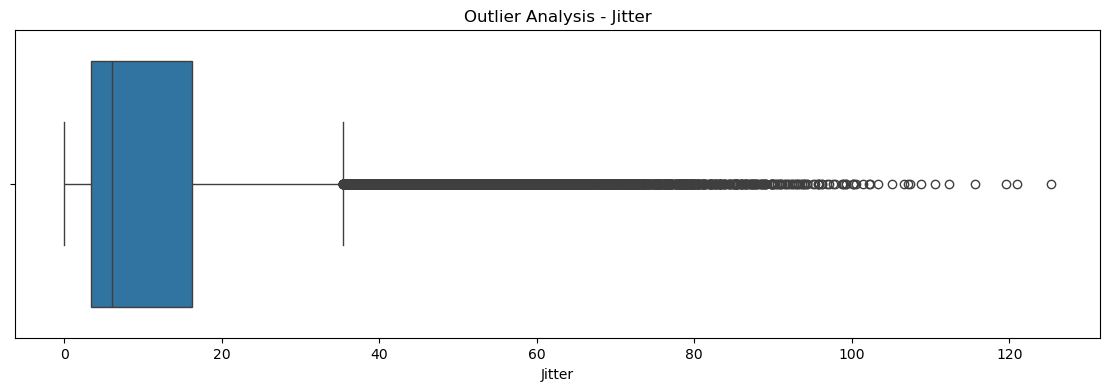

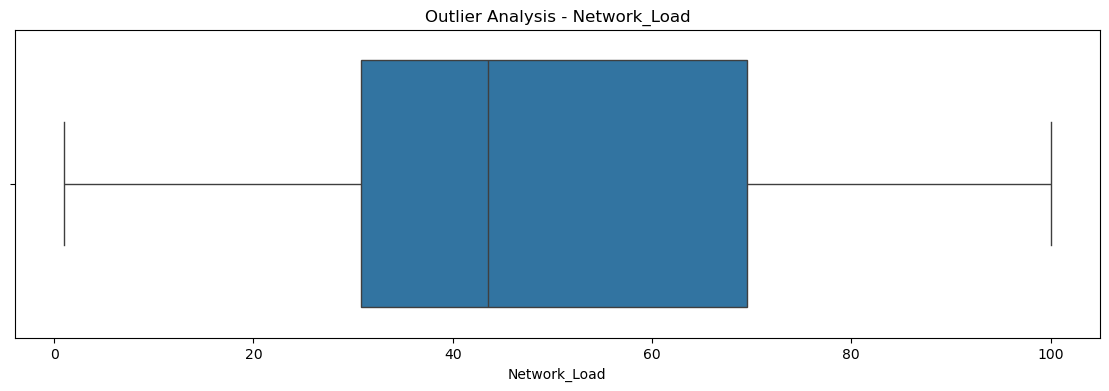

In [85]:
#outlier analysis
cols = [
    "Latency",
    "Throughput",
    "Packet_Loss",
    "Jitter",
    "Network_Load"
]
#loop the each column for sparate chart
for col in cols:
    plt.figure(figsize=(14, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Analysis - {col}")
    plt.show()

percentage_of Network_Status
Normal       68.30
Congested    21.83
Fault         9.87
Name: proportion, dtype: float64
Network_Status
Normal       34494
Congested    11022
Fault         4984
Name: count, dtype: int64


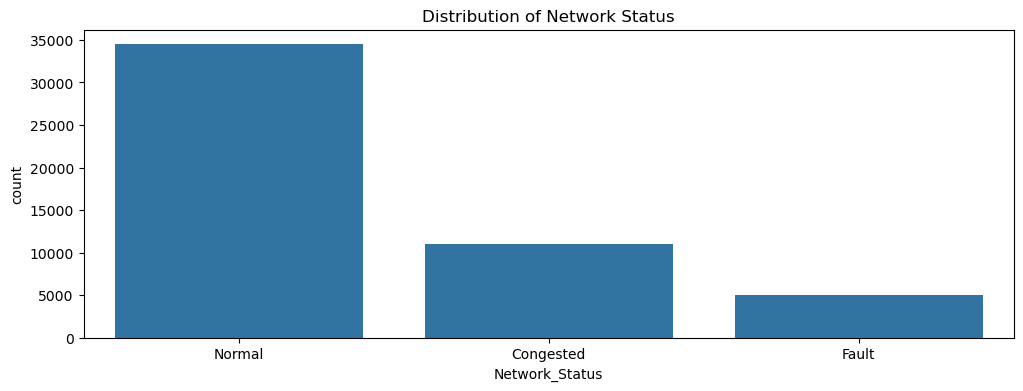

In [87]:
Network_Status_in_percentage=df['Network_Status'].value_counts(normalize=True)*100
print('percentage_of',Network_Status_in_percentage.round(2))
print(df['Network_Status'].value_counts())

plt.figure(figsize=(12, 4))    
sns.countplot(data=df,x='Network_Status')
plt.title("Distribution of Network Status")
plt.show()

average latency : 1036426.6796666667


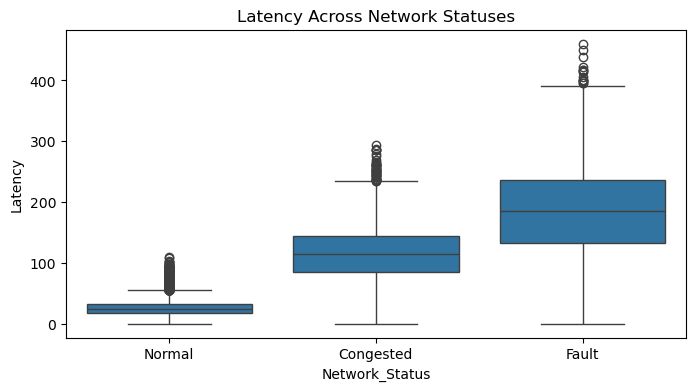

In [89]:
print('average latency :',df.groupby('Network_Status')['Latency'].sum().mean())

plt.figure(figsize=(8, 4))
sns.boxplot(data=df,x='Network_Status',y='Latency')
plt.title('Latency Across Network Statuses')
plt.show()

Congestion_Level
High      80.443592
Low       36.779213
Medium    60.592436
Severe    80.231212
Name: Network_Load, dtype: float64


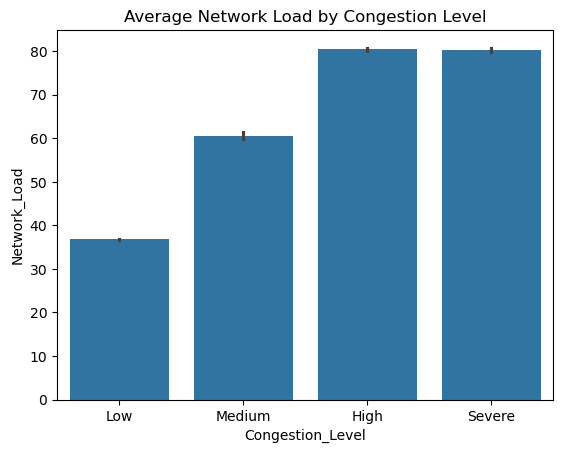

In [44]:
print(df.groupby('Congestion_Level')['Network_Load'].mean())

sns.barplot(data=df,x='Congestion_Level',y='Network_Load')
plt.title('Average Network Load by Congestion Level')
plt.show()

In [46]:
#network performance category
df['latency_category']=np.select(
    [df['Latency']<50,
     df['Latency'].between(50,100,inclusive='left'),
     df['Latency']>=100],
    
    ['low latency',
     'medium latency',
     'high latency'],
    default='unknown')
print(df['latency_category'].value_counts())

latency_category
low latency       33609
high latency      11222
medium latency     5669
Name: count, dtype: int64


In [50]:
#transfer byte to mb
df['data_transfer_mb']=df['Byte_Count']/(1024**2)

print(df['data_transfer_mb'].describe())

count    50500.000000
mean        16.140391
std         26.960152
min          0.002611
25%          0.322662
50%          4.620447
75%         19.302424
max        315.053513
Name: data_transfer_mb, dtype: float64


In [52]:
#category of network load
df['load_category']=np.select(
    [df['Network_Load']<40,
     df['Network_Load'].between(40,70,inclusive='left'),
     df['Network_Load']>=70],
    ['low load',
     'medium load',
     'high load'],
    default='unknown')

print(df['load_category'].value_counts())

load_category
low load       21909
medium load    16102
high load      12489
Name: count, dtype: int64


In [53]:
performance_summary = df.groupby("Network_Status").agg(
    Average_Latency=("Latency", "mean"),
    Average_Throughput=("Throughput", "mean"),
    Average_Packet_Loss=("Packet_Loss", "mean"),
    Average_Jitter=("Jitter", "mean"),
    Average_Network_Load=("Network_Load", "mean")
)

print(performance_summary.round(2))

                Average_Latency  Average_Throughput  Average_Packet_Loss  \
Network_Status                                                             
Congested                114.60                6.46                 3.25   
Fault                    185.48                3.11                 9.66   
Normal                    26.72                6.26                 0.23   

                Average_Jitter  Average_Network_Load  
Network_Status                                        
Congested                24.36                 85.62  
Fault                    42.51                 60.73  
Normal                    4.65                 36.07  


In [54]:
fault_analysis = df.groupby("Network_Status").agg(
    Average_Latency=("Latency", "mean"),
    Average_Load=("Network_Load", "mean"),
    Average_Failures=("Failure_Count", "mean"),
    Average_Packet_Loss=("Packet_Loss", "mean")
)

print(fault_analysis.round(2))

                Average_Latency  Average_Load  Average_Failures  \
Network_Status                                                    
Congested                114.60         85.62              0.52   
Fault                    185.48         60.73              2.24   
Normal                    26.72         36.07              0.07   

                Average_Packet_Loss  
Network_Status                       
Congested                      3.25  
Fault                          9.66  
Normal                         0.23  


In [66]:
service_faults = (
    df.assign(Is_Fault=df["Network_Status"].eq("Fault"))
      .groupby("Service_Type")
      .agg(
          Total_Flows=("Network_Status", "size"),
          Fault_Count=("Is_Fault", "sum"),
          Fault_Rate=("Is_Fault", "mean")
      )
)

service_faults["Fault_Rate"] *= 100

print(service_faults.sort_values("Fault_Rate", ascending=False))

                 Total_Flows  Fault_Count  Fault_Rate
Service_Type                                         
AR_VR                   1991          213   10.698142
Enterprise_VPN          4633          480   10.360458
VoIP                    6007          604   10.054936
Web_Browsing           11612         1153    9.929383
Video_Streaming        10690         1048    9.803555
Gaming                  4145          405    9.770808
IoT_Telemetry           6505          624    9.592621
Messaging               4917          457    9.294285


In [67]:
df.head(10)

,Flow_ID,Protocol_Type,Flow_Duration,Packet_Count,Byte_Count,Throughput,Latency,Packet_Loss,Jitter,Bandwidth_Utilization,Network_Load,Service_Type,Failure_Count,Congestion_Level,Network_Status,latency_category,data_transfer_mb,load_category
0,FLOW_00000001,RTP,220.905,145,60755,0.0897,26.463,0.4684,4.625,40.405,15.650,VoIP,0,Low,Normal,low latency,0.057940,low load
1,FLOW_00000002,TCP,520.024,6082,5029814,0.6325,14.851,0.4386,3.143,20.280,44.621,Web_Browsing,0,Low,Normal,low latency,4.796804,medium load
2,FLOW_00000003,TCP,519.877,69292,88485884,6.0344,78.080,2.3449,30.547,87.927,86.616,Video_Streaming,0,Medium,Congested,medium latency,84.386715,high load
3,FLOW_00000004,MQTT,1372.757,1863,111780,0.2189,36.255,0.1877,1.181,75.056,26.294,IoT_Telemetry,0,Low,Normal,low latency,0.106602,low load
4,FLOW_00000005,HTTP2,2.286,5186,6658824,13.8181,22.979,0.1661,4.226,36.957,37.454,Web_Browsing,0,Low,Normal,low latency,6.350349,low load
5,FLOW_00000006,TCP,1.956,1529,422004,0.6503,25.836,4.0532,43.401,94.630,82.787,Messaging,0,High,Congested,low latency,0.402454,high load
6,FLOW_00000007,UDP,3448.574,54029,10589684,8.1197,33.973,0.3036,5.428,23.397,36.657,Enterprise_VPN,0,Low,Normal,low latency,10.099110,low load
7,FLOW_00000008,QUIC,3594.467,15251,7869516,7.9283,13.218,0.3172,6.555,52.194,32.722,Video_Streaming,0,Low,Normal,low latency,7.504955,low load
8,FLOW_00000009,TCP,2488.452,83050,92600750,11.2086,34.480,0.5325,1.248,55.171,35.803,Enterprise_VPN,0,Low,Normal,low latency,88.310957,low load
9,FLOW_00000010,TCP,1200.813,1180,444860,0.0545,191.233,12.7827,34.728,81.431,71.036,IoT_Telemetry,4,Low,Fault,high latency,0.424252,high load


In [49]:

# Professional network status colors
status_colors = {
    "Normal": "#2A9D8F",
    "Congested": "#E9C46A",
    "Fault": "#E76F51"
}

# Professional protocol colors
protocol_palette = sns.color_palette("deep")

# General chart settings
sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.05,
    rc={
        "figure.facecolor": "#FFFFFF",
        "axes.facecolor": "#FFFFFF",
        "axes.edgecolor": "#D9E2EC",
        "grid.color": "#D9E2EC",
        "axes.titleweight": "bold",
        "axes.labelcolor": "#264653",
        "text.color": "#264653",
        "xtick.color": "#264653",
        "ytick.color": "#264653"
    }
)

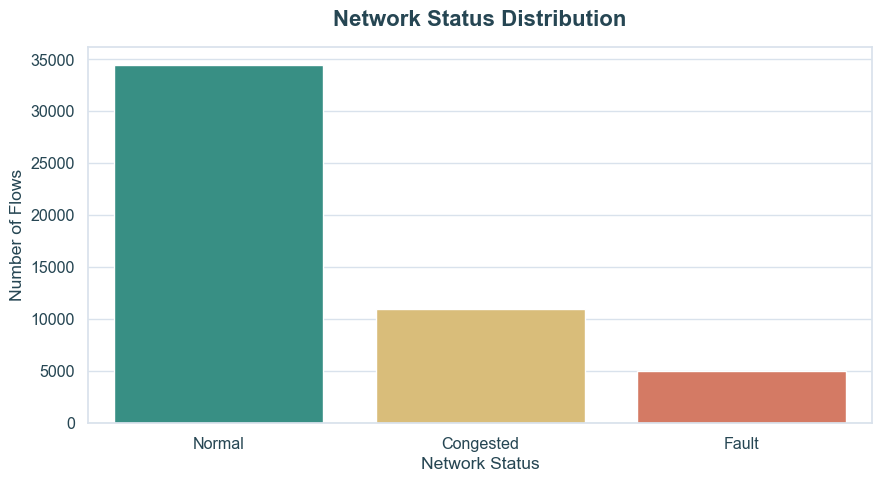

In [50]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Network_Status",
    hue="Network_Status",
    order=["Normal", "Congested", "Fault"],
    palette=status_colors,
    legend=False
)

plt.title("Network Status Distribution", fontsize=16, pad=15)
plt.xlabel("Network Status")
plt.ylabel("Number of Flows")
plt.tight_layout()
plt.show()

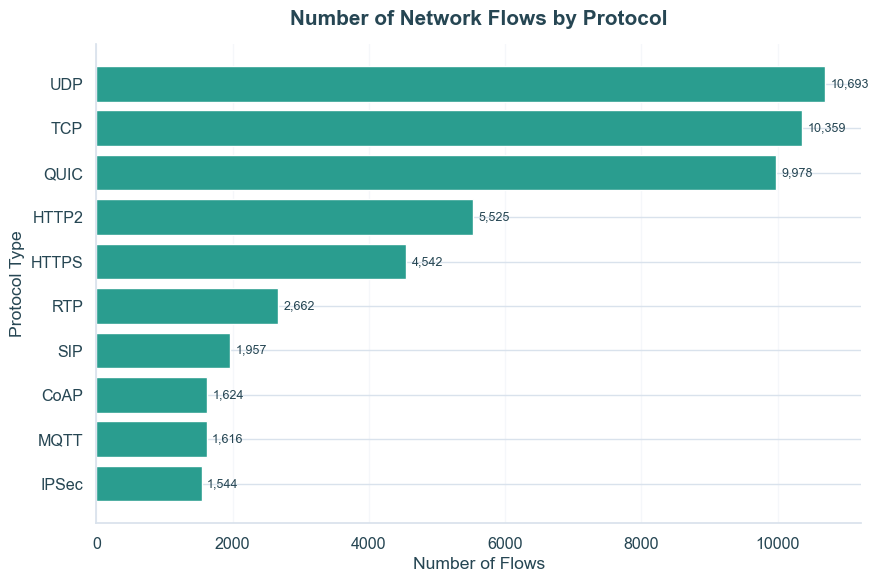

In [57]:
protocol_counts = df["Protocol_Type"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(protocol_counts.index, protocol_counts.values, color="#2A9D8F")
ax.bar_label(bars, labels=[f"{v:,}" for v in protocol_counts.values], padding=4, fontsize=9)
ax.set_title("Number of Network Flows by Protocol", fontsize=15, fontweight="bold", pad=14)
ax.set_xlabel("Number of Flows")
ax.set_ylabel("Protocol Type")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

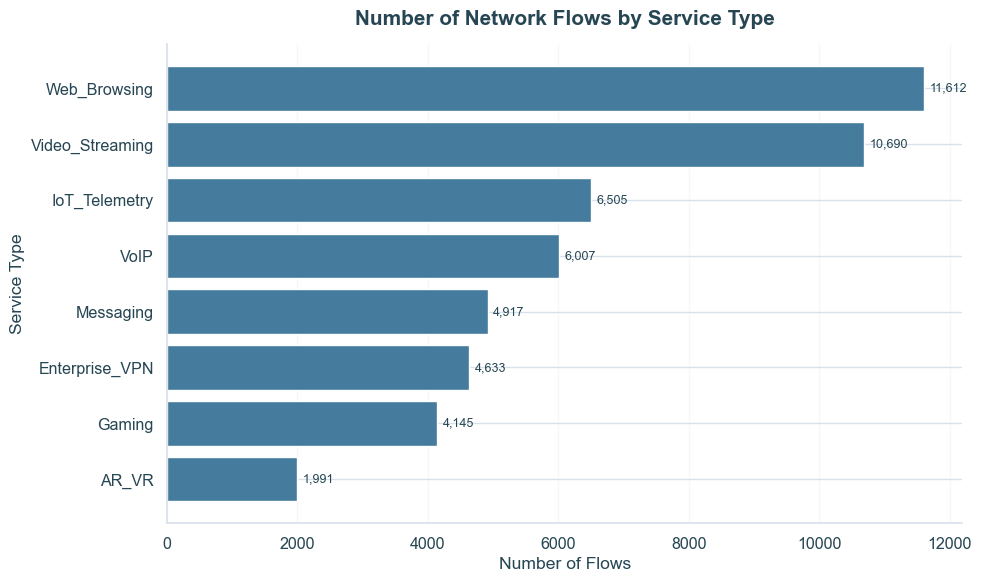

In [59]:
service_counts = df["Service_Type"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(service_counts.index, service_counts.values, color="#457B9D")
ax.bar_label(bars, labels=[f"{v:,}" for v in service_counts.values], padding=4, fontsize=9)
ax.set_title("Number of Network Flows by Service Type", fontsize=15, fontweight="bold", pad=14)
ax.set_xlabel("Number of Flows")
ax.set_ylabel("Service Type")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

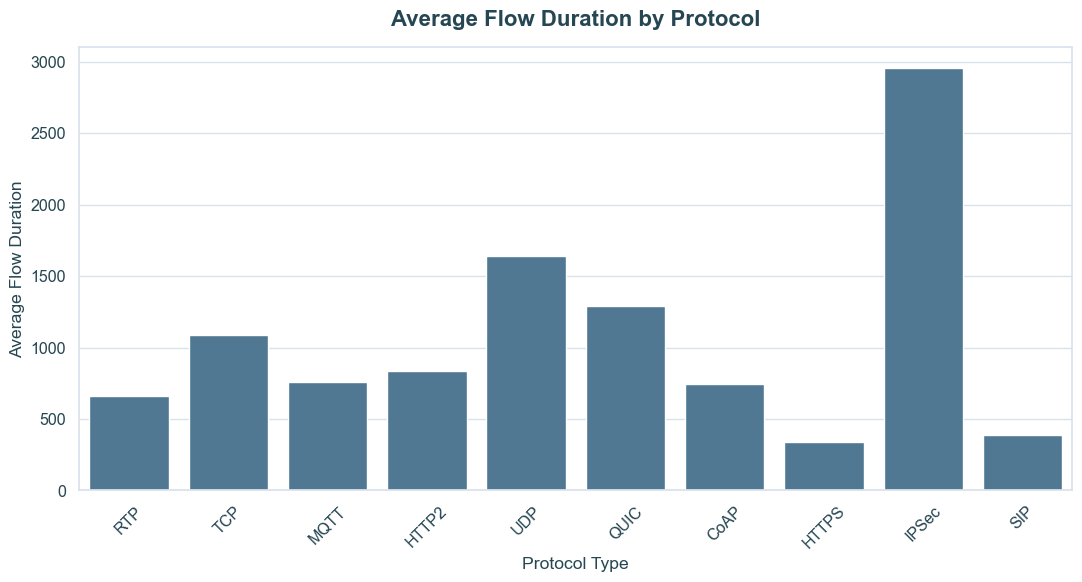

In [51]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=df,
    x="Protocol_Type",
    y="Flow_Duration",
    color="#457B9D",
    errorbar=None
)

plt.title("Average Flow Duration by Protocol", fontsize=16, pad=15)
plt.xlabel("Protocol Type")
plt.ylabel("Average Flow Duration")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

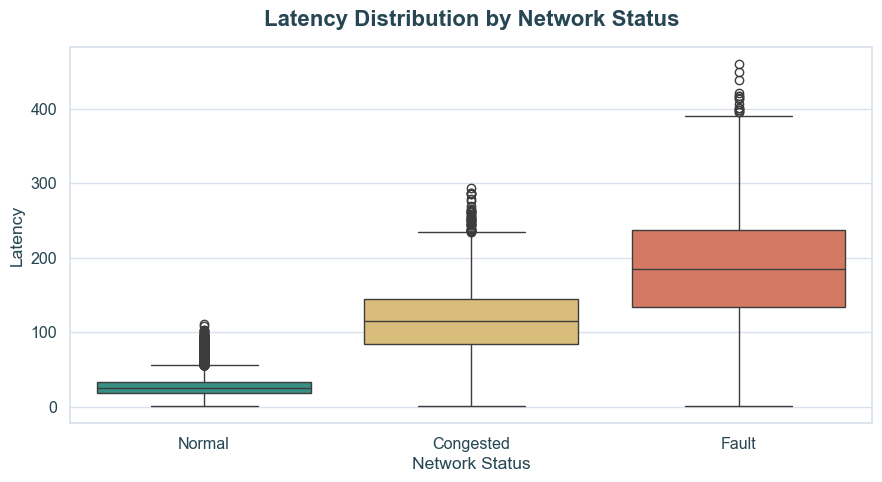

In [52]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Network_Status",
    y="Latency",
    hue="Network_Status",
    order=["Normal", "Congested", "Fault"],
    palette=status_colors,
    legend=False
)

plt.title("Latency Distribution by Network Status", fontsize=16, pad=15)
plt.xlabel("Network Status")
plt.ylabel("Latency")
plt.tight_layout()
plt.show()

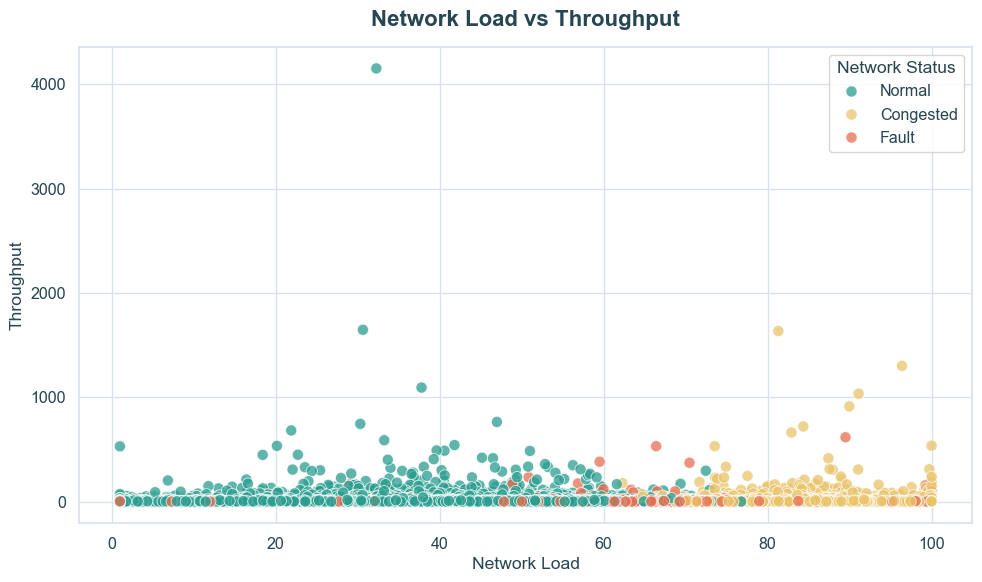

In [53]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Network_Load",
    y="Throughput",
    hue="Network_Status",
    palette=status_colors,
    alpha=0.75,
    s=65
)

plt.title("Network Load vs Throughput", fontsize=16, pad=15)
plt.xlabel("Network Load")
plt.ylabel("Throughput")
plt.legend(title="Network Status", frameon=True)
plt.tight_layout()
plt.show()

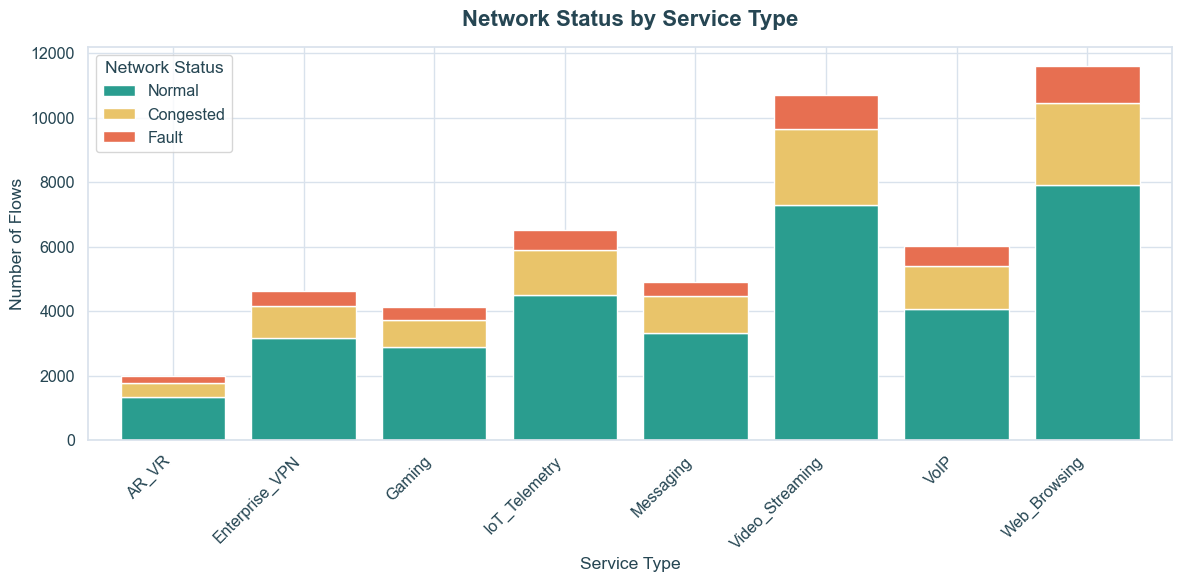

In [55]:
status_table = pd.crosstab(
    df["Service_Type"],
    df["Network_Status"]
)

status_table = status_table.reindex(
    columns=["Normal", "Congested", "Fault"],
    fill_value=0
)

status_table.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=[
        status_colors["Normal"],
        status_colors["Congested"],
        status_colors["Fault"]
    ],
    width=0.8
)

plt.title("Network Status by Service Type", fontsize=16, pad=15)
plt.xlabel("Service Type")
plt.ylabel("Number of Flows")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Network Status")
plt.tight_layout()
plt.show()

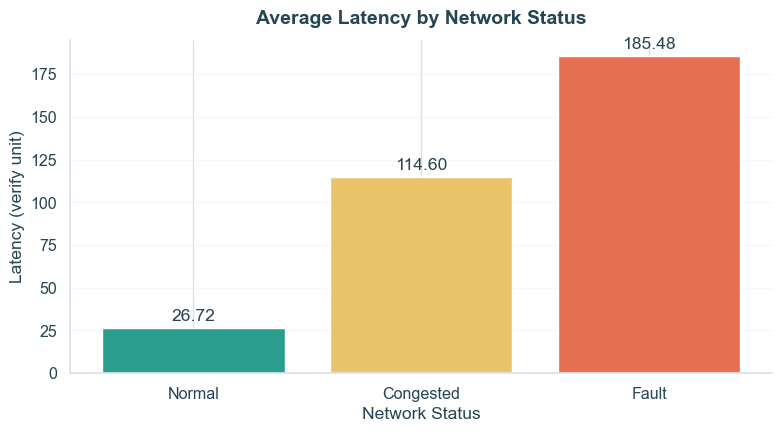

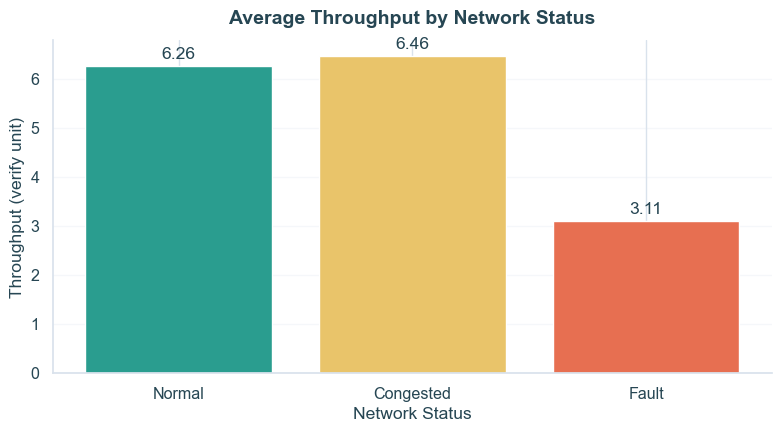

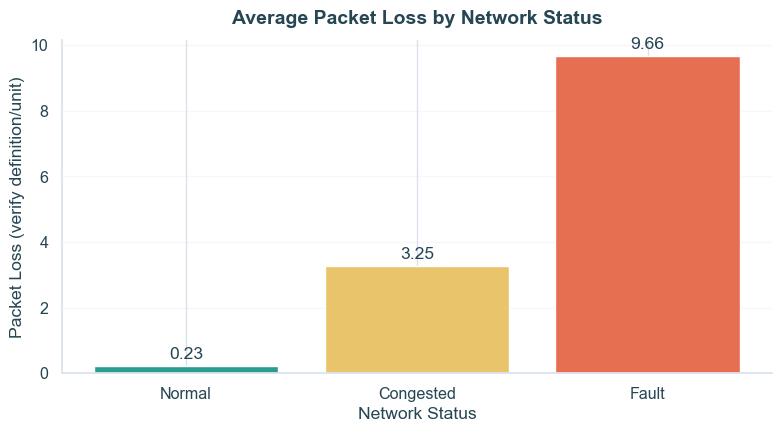

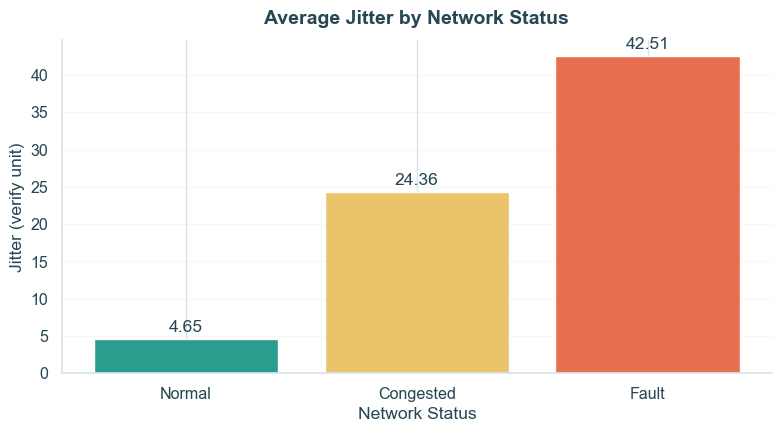

In [60]:
metric_specs = [
    ("Latency", "Average Latency by Network Status", "Latency (verify unit)"),
    ("Throughput", "Average Throughput by Network Status", "Throughput (verify unit)"),
    ("Packet_Loss", "Average Packet Loss by Network Status", "Packet Loss (verify definition/unit)"),
    ("Jitter", "Average Jitter by Network Status", "Jitter (verify unit)")
]
status_order = ["Normal", "Congested", "Fault"]

for column, title, ylabel in metric_specs:
    summary = df.groupby("Network_Status")[column].mean().reindex(status_order)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(summary.index, summary.values,
                  color=[status_colors[s] for s in summary.index])
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in summary.values], padding=3)
    ax.set_title(title, fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel("Network Status")
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

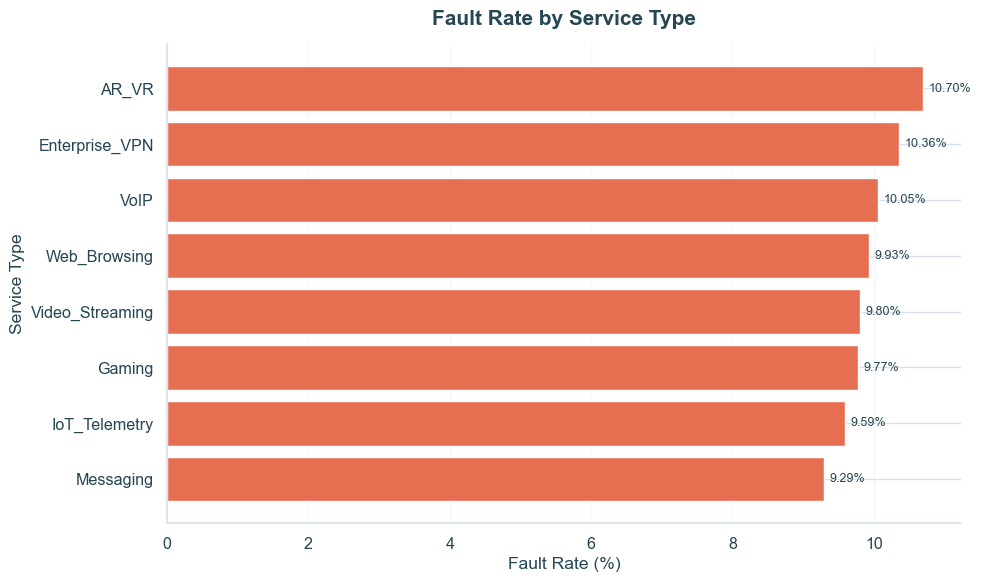

,Total_Flows,Fault_Count,Fault_Rate
Service_Type,,,
AR_VR,1991,213,10.70
Enterprise_VPN,4633,480,10.36
VoIP,6007,604,10.05
Web_Browsing,11612,1153,9.93
Video_Streaming,10690,1048,9.80
Gaming,4145,405,9.77
IoT_Telemetry,6505,624,9.59
Messaging,4917,457,9.29


In [61]:
service_faults = (
    df.assign(Is_Fault=df["Network_Status"].eq("Fault"))
      .groupby("Service_Type")
      .agg(Total_Flows=("Network_Status", "size"),
           Fault_Count=("Is_Fault", "sum"),
           Fault_Rate=("Is_Fault", "mean"))
)
service_faults["Fault_Rate"] *= 100
service_faults = service_faults.sort_values("Fault_Rate")

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(service_faults.index, service_faults["Fault_Rate"], color="#E76F51")
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in service_faults["Fault_Rate"]], padding=4, fontsize=9)
ax.set_title("Fault Rate by Service Type", fontsize=15, fontweight="bold", pad=14)
ax.set_xlabel("Fault Rate (%)")
ax.set_ylabel("Service Type")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(service_faults.sort_values("Fault_Rate", ascending=False).round(2))

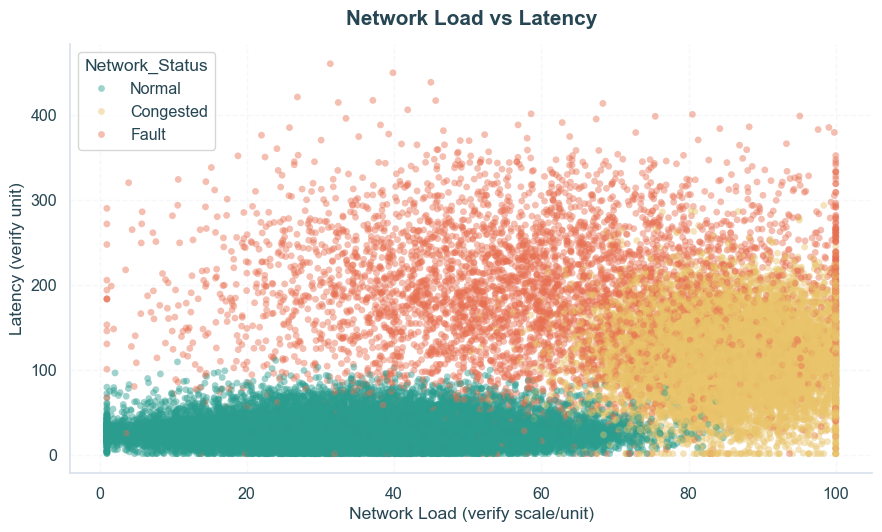

In [62]:
# Define colors directly in this cell
STATUS_COLORS = {
    "Normal": "#2A9D8F",
    "Congested": "#E9C46A",
    "Fault": "#E76F51"
}

# Create scatter plot
fig, ax = plt.subplots(figsize=(9, 5.5))

sns.scatterplot(
    data=df,
    x="Network_Load",
    y="Latency",
    hue="Network_Status",
    hue_order=["Normal", "Congested", "Fault"],
    palette=STATUS_COLORS,
    alpha=0.45,
    s=24,
    linewidth=0,
    ax=ax
)

ax.set_title(
    "Network Load vs Latency",
    fontsize=15,
    fontweight="bold",
    pad=14
)

ax.set_xlabel("Network Load (verify scale/unit)")
ax.set_ylabel("Latency (verify unit)")
ax.grid(True, linestyle="--", alpha=0.25)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()